In [124]:
# ==========================================
# DEVELOPERS ARENA - WEEK 6
# Interactive Sales Analytics Dashboard
# ==========================================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Interactive visualization
import plotly.express as px
import plotly.graph_objects as go

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Visualization theme
sns.set_theme(style="whitegrid", palette="muted")

# Default figure size
plt.rcParams['figure.figsize'] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [125]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\Asus\developers-arena-python-tasks\Week-6-Interactive-Sales-Dashboard\data\sales_data.csv",
    encoding="latin1"
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (100, 7)


,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales
0,2024-01-01,Phone,7,37300,CUST001,East,261100
1,2024-01-02,Headphones,4,15406,CUST002,North,61624
2,2024-01-03,Phone,2,21746,CUST003,West,43492
3,2024-01-04,Headphones,1,30895,CUST004,East,30895
4,2024-01-05,Laptop,8,39835,CUST005,North,318680


In [126]:
print("Dataset Columns:")
for column in df.columns:
    print(column)

Dataset Columns:
Date
Product
Quantity
Price
Customer_ID
Region
Total_Sales


In [127]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Date         100 non-null    object
 1   Product      100 non-null    object
 2   Quantity     100 non-null    int64 
 3   Price        100 non-null    int64 
 4   Customer_ID  100 non-null    object
 5   Region       100 non-null    object
 6   Total_Sales  100 non-null    int64 
dtypes: int64(3), object(4)
memory usage: 5.6+ KB


In [128]:
df.describe().round(2)

,Quantity,Price,Total_Sales
count,100.00,100.00,100.00
mean,4.78,25808.51,123650.48
std,2.59,13917.63,100161.09
min,1.00,1308.00,6540.00
25%,2.75,14965.25,39517.50
50%,5.00,24192.00,97955.50
75%,7.00,38682.25,175792.50
max,9.00,49930.00,373932.00


In [129]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values[missing_values > 0])

Missing Values:
Series([], dtype: int64)


In [130]:
print("Total Duplicate Records:", df.duplicated().sum())

Total Duplicate Records: 0


In [131]:
df.dtypes

Date           object
Product        object
Quantity        int64
Price           int64
Customer_ID    object
Region         object
Total_Sales     int64
dtype: object

In [132]:
# Configure visualization theme

sns.set_theme(
    style="whitegrid",
    palette="deep",
    font_scale=1.1
)

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 12

print("Visualization theme configured successfully!")

Visualization theme configured successfully!


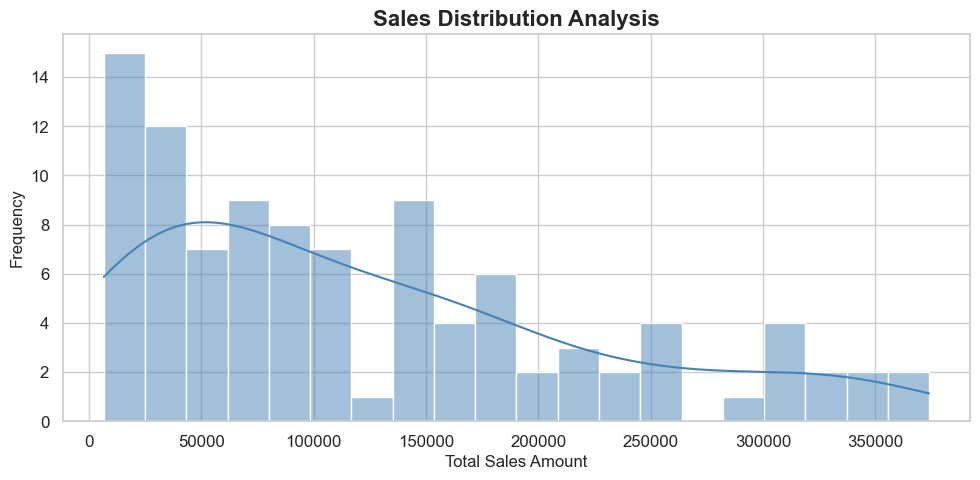

In [133]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Total_Sales',
    bins=20,
    kde=True,
    color='steelblue'
)

plt.title('Sales Distribution Analysis')
plt.xlabel('Total Sales Amount')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

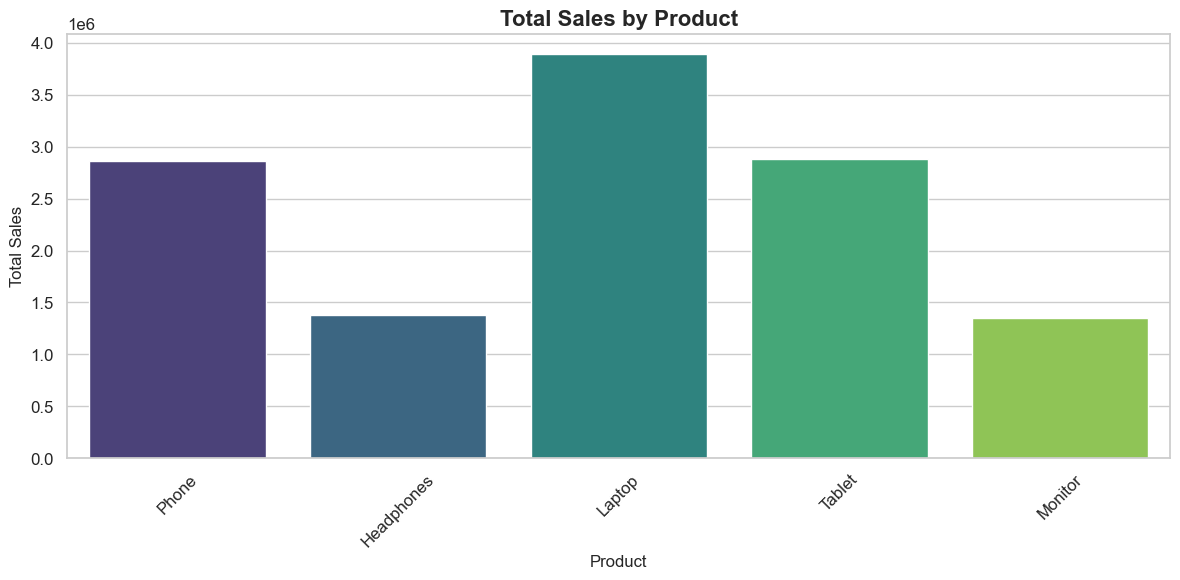

In [134]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x='Product',
    y='Total_Sales',
    estimator='sum',
    errorbar=None,
    hue='Product',
    legend=False,
    palette='viridis'
)

plt.title('Total Sales by Product')
plt.xlabel('Product')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

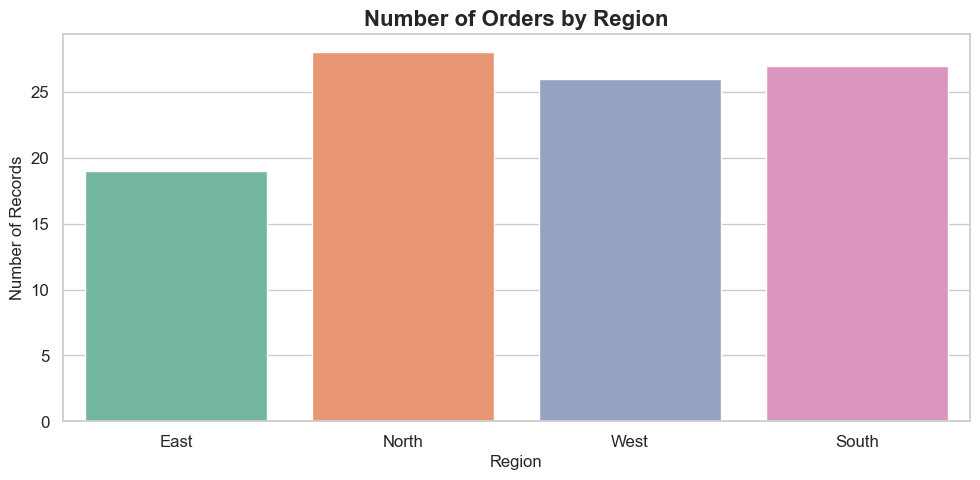

In [135]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='Region',
    hue='Region',
    legend=False,
    palette='Set2'
)

plt.title('Number of Orders by Region')
plt.xlabel('Region')
plt.ylabel('Number of Records')

plt.tight_layout()
plt.show()

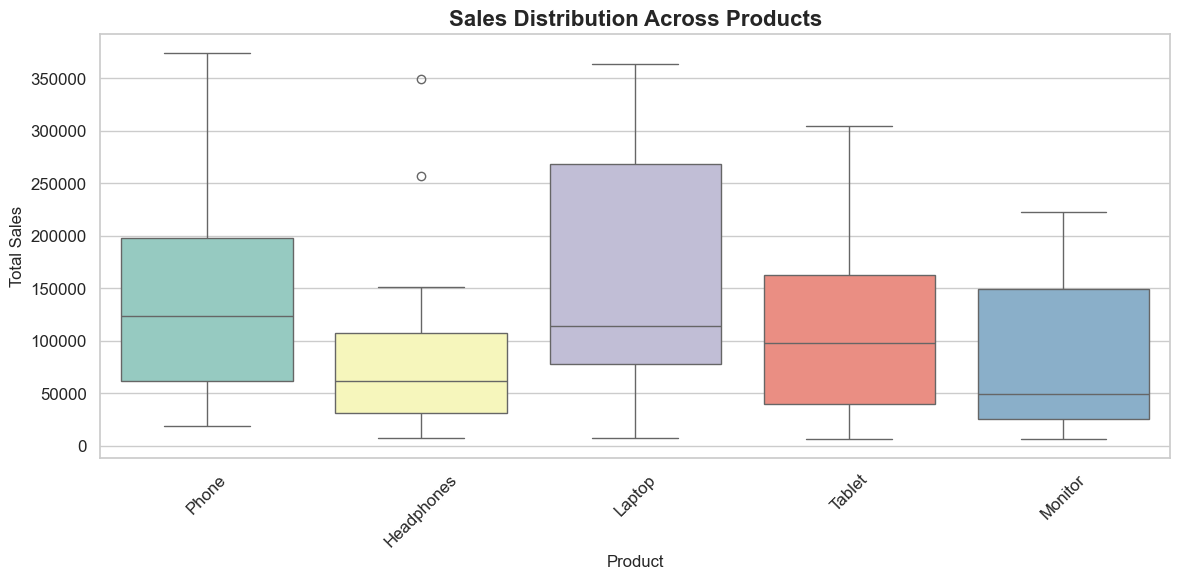

In [136]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='Product',
    y='Total_Sales',
    hue='Product',
    legend=False,
    palette='Set3'
)

plt.title('Sales Distribution Across Products')
plt.xlabel('Product')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

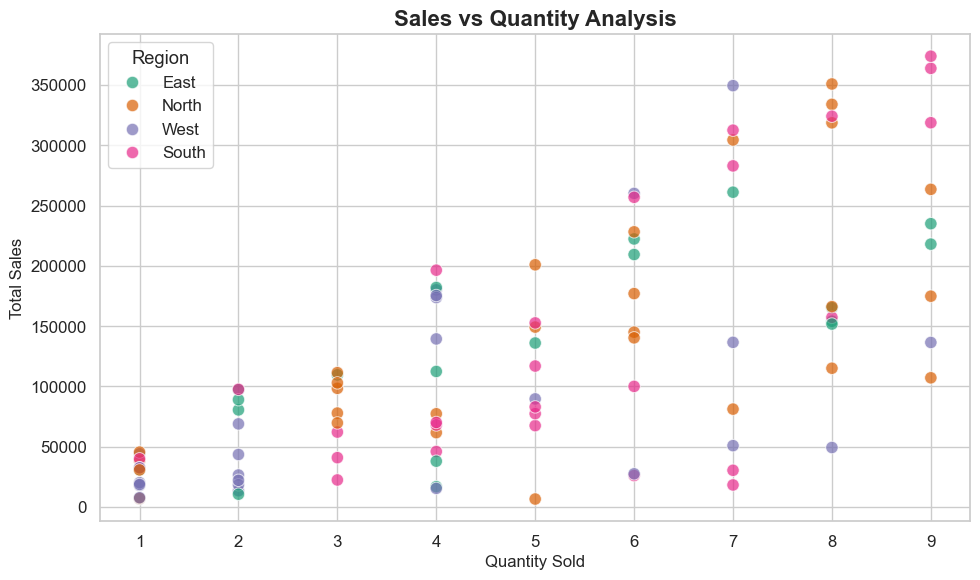

In [137]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Quantity',
    y='Total_Sales',
    hue='Region',
    alpha=0.7,
    palette='Dark2',
    s=80
)

plt.title('Sales vs Quantity Analysis')
plt.xlabel('Quantity Sold')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

In [138]:
import os

os.makedirs("visualizations", exist_ok=True)

print("Visualization folder ready!")

Visualization folder ready!


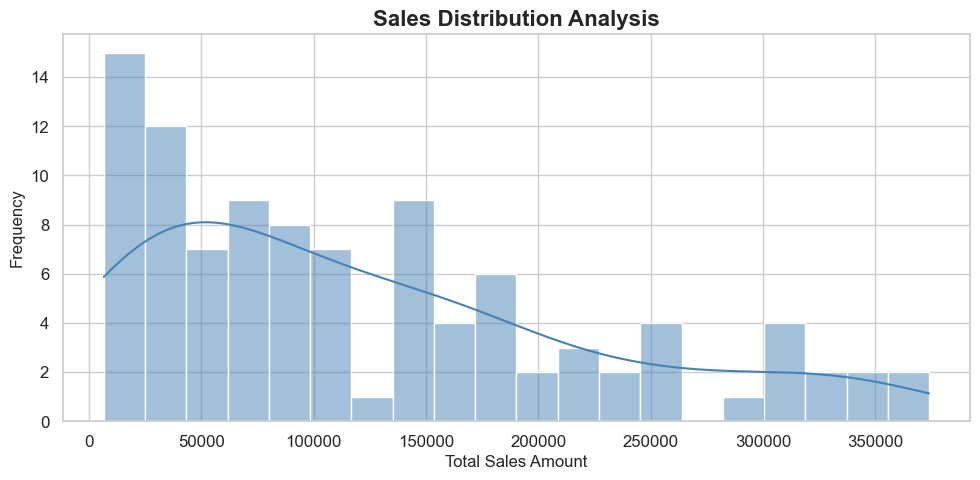

In [139]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Total_Sales',
    bins=20,
    kde=True,
    color='steelblue'
)

plt.title('Sales Distribution Analysis')
plt.xlabel('Total Sales Amount')
plt.ylabel('Frequency')

plt.tight_layout()

plt.savefig(
    'visualizations/sales_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

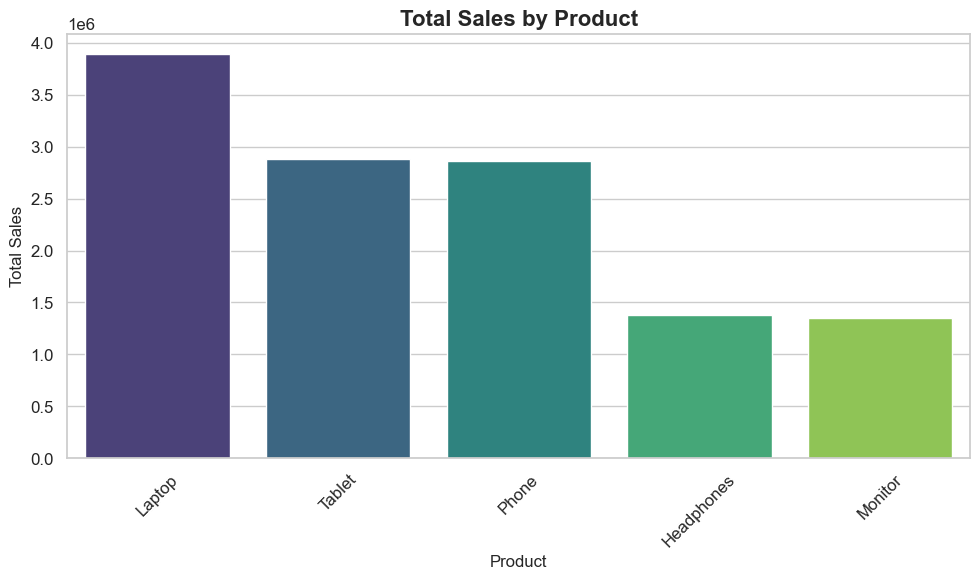

In [140]:
plt.figure(figsize=(10, 6))

product_sales = (
    df.groupby('Product')['Total_Sales']
    .sum()
    .reset_index()
    .sort_values('Total_Sales', ascending=False)
)

sns.barplot(
    data=product_sales,
    x='Product',
    y='Total_Sales',
    hue='Product',
    palette='viridis',
    legend=False
)

plt.title(
    'Total Sales by Product',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Product')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    'visualizations/sales_by_product.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

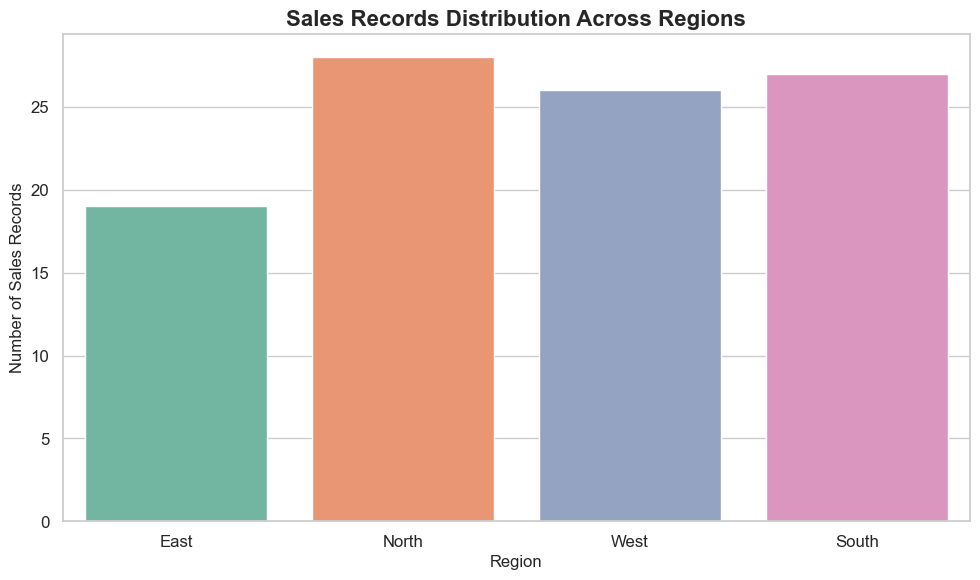

In [141]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='Region',
    hue='Region',
    palette='Set2',
    legend=False
)

plt.title(
    'Sales Records Distribution Across Regions',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Region')
plt.ylabel('Number of Sales Records')

plt.tight_layout()

plt.savefig(
    'visualizations/orders_by_region.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

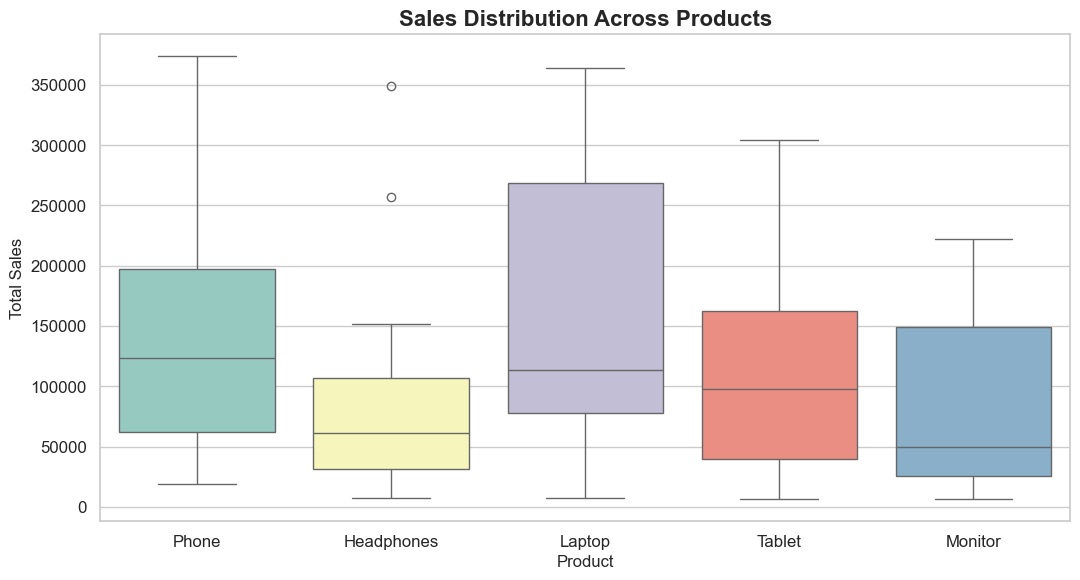

In [143]:
# ==========================================
# SALES DISTRIBUTION ACROSS PRODUCTS
# ==========================================

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x='Product',
    y='Total_Sales',
    hue='Product',
    palette='Set3',
    legend=False
)

plt.title(
    'Sales Distribution Across Products',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Product')
plt.ylabel('Total Sales')

plt.tight_layout()

plt.savefig(
    'visualizations/sales_distribution_by_product.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [144]:
sales_analysis = df.groupby('Product')['Total_Sales'].agg(
    ['mean', 'median', 'min', 'max', 'std']
).round(2)

sales_analysis

,mean,median,min,max,std
Product,,,,,
Headphones,92268.87,61624.0,7647,349510,96176.96
Laptop,162050.42,113720.0,7148,363870,116569.89
Monitor,89871.40,49280.0,6720,222330,77595.27
Phone,142969.70,123922.5,18616,373932,107191.55
Tablet,110936.15,97788.5,6540,304465,82366.53


In [145]:
# Sales vs Profit Analysis

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x='Sales',
    y='Profit',
    hue='Category',
    palette='Dark2',
    alpha=0.65,
    s=60
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Zero Profit'
)

plt.title(
    'Sales vs Profit Analysis',
    fontsize=17,
    fontweight='bold'
)

plt.xlabel('Sales Revenue ($)')
plt.ylabel('Profit ($)')

plt.legend(title='Product Category')

plt.tight_layout()

plt.savefig(
    'visualizations/sales_vs_profit.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

ValueError: Could not interpret value `Sales` for `x`. An entry with this name does not appear in `data`.

<Figure size 1200x700 with 0 Axes>

In [146]:
correlation = df[['Sales', 'Profit']].corr()

print("Sales-Profit Correlation:")
display(correlation)

KeyError: "None of [Index(['Sales', 'Profit'], dtype='object')] are in the [columns]"

In [147]:
import os

print("Saved Visualizations:")

for file in os.listdir("visualizations"):
    print("✔", file)

Saved Visualizations:
✔ advanced_boxplot.png
✔ advanced_correlation_heatmap.png
✔ correlation_heatmap.png
✔ customer_performance.html
✔ customer_segmentation.html
✔ interactive_category_sales.html
✔ interactive_product_sales.html
✔ interactive_regional_profit.html
✔ interactive_regional_sales.html
✔ monthly_sales_trend.png
✔ orders_by_region.png
✔ product_performance_treemap.html
✔ profit_distribution.png
✔ profit_statistical_annotations.png
✔ sales_by_category.png
✔ sales_by_product.png
✔ sales_distribution.png
✔ sales_distribution_by_product.png
✔ sales_outlier_boxplot.png
✔ sales_outlier_detection.png
✔ sales_subplot_dashboard.png
✔ sales_vs_profit.png
✔ statistical_annotations.png
✔ violin_profit_distribution.png
✔ violin_sales_distribution.png


In [148]:
print("========== SALES ANALYSIS ==========")

# Total Revenue
print("\nTotal Revenue:")
print(round(df['Total_Sales'].sum(), 2))

# Total Quantity Sold
print("\nTotal Quantity Sold:")
print(df['Quantity'].sum())

# Total Unique Customers
print("\nTotal Unique Customers:")
print(df['Customer_ID'].nunique())

# Best Performing Product
print("\nBest Performing Product:")
print(
    df.groupby('Product')['Total_Sales']
    .sum()
    .idxmax()
)

# Best Performing Region
print("\nBest Performing Region:")
print(
    df.groupby('Region')['Total_Sales']
    .sum()
    .idxmax()
)

# Average Sales per Record
print("\nAverage Sales per Record:")
print(round(df['Total_Sales'].mean(), 2))

# Highest Sales Transaction
print("\nHighest Sales Transaction:")
print(round(df['Total_Sales'].max(), 2))

print("\n====================================")

========== SALES ANALYSIS ==========

Total Revenue:
12365048

Total Quantity Sold:
478

Total Unique Customers:
100

Best Performing Product:
Laptop

Best Performing Region:
North

Average Sales per Record:
123650.48

Highest Sales Transaction:
373932



In [149]:
# Calculate total revenue
total_revenue = df['Total_Sales'].sum()

# Calculate revenue by product
product_revenue = (
    df.groupby('Product')['Total_Sales']
    .sum()
)

# Calculate revenue contribution percentage
revenue_contribution = (
    product_revenue / total_revenue
) * 100

print("========== REVENUE ANALYSIS ==========")

print(f"\nTotal Revenue: ${total_revenue:,.2f}")

print("\nRevenue Contribution by Product:")

print(revenue_contribution.round(2))

print("\n======================================")

========== REVENUE ANALYSIS ==========

Total Revenue: $12,365,048.00

Revenue Contribution by Product:
Product
Headphones    11.19
Laptop        31.45
Monitor       10.90
Phone         23.12
Tablet        23.33
Name: Total_Sales, dtype: float64



In [150]:
print("Dataset Shape:", df.shape)
print("Available Products:", df['Product'].unique())
print("Total Records:", len(df))
print("Available Regions:", df['Region'].unique())

Dataset Shape: (100, 7)
Available Products: ['Phone' 'Headphones' 'Laptop' 'Tablet' 'Monitor']
Total Records: 100
Available Regions: ['East' 'North' 'West' 'South']


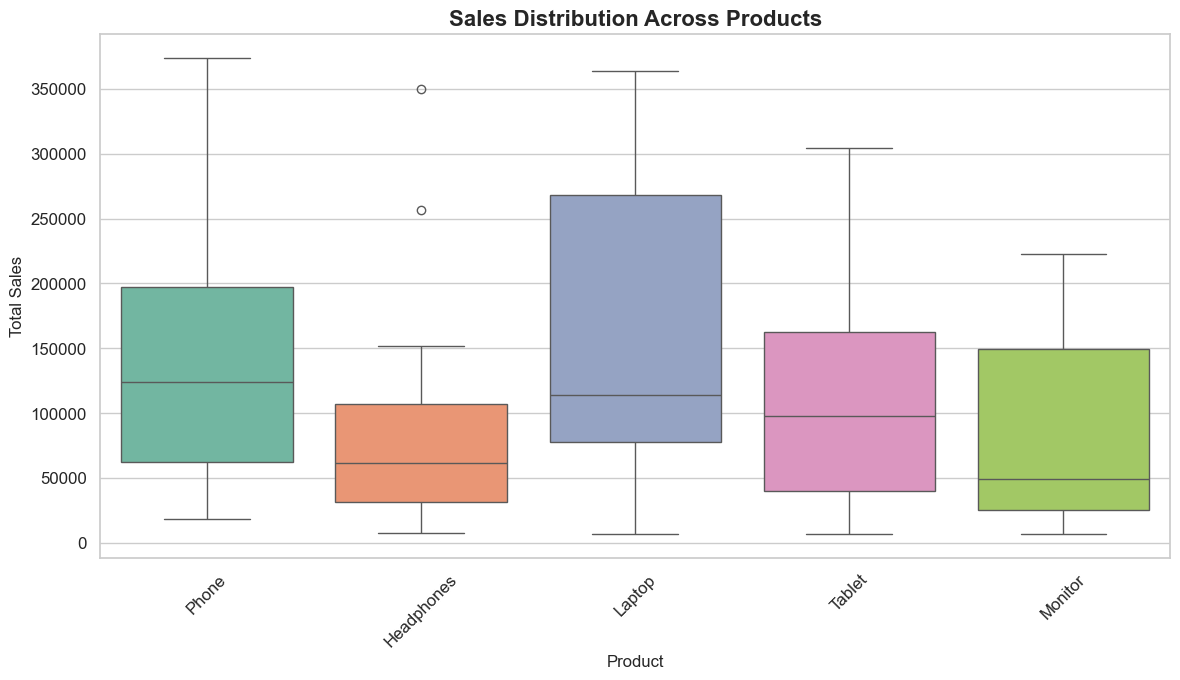

In [151]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x='Product',
    y='Total_Sales',
    hue='Product',
    palette='Set2',
    legend=False,
    showfliers=True
)

plt.title(
    'Sales Distribution Across Products',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Product')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    'visualizations/advanced_boxplot.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

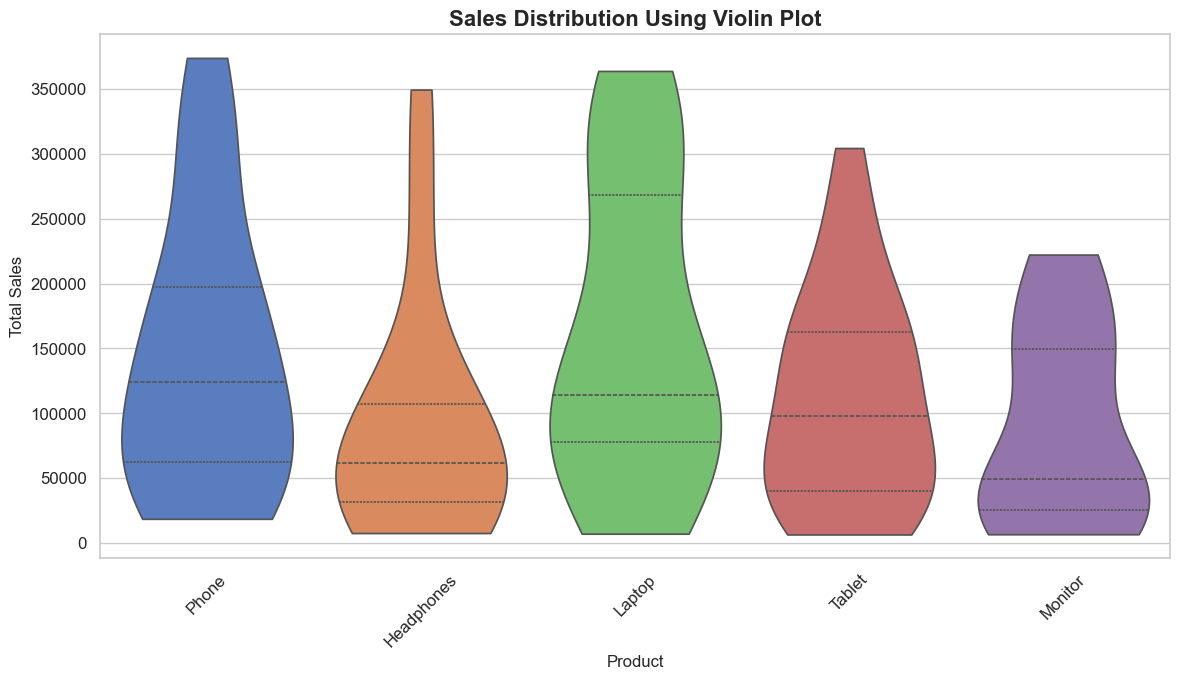

In [152]:
plt.figure(figsize=(12, 7))

sns.violinplot(
    data=df,
    x='Product',
    y='Total_Sales',
    hue='Product',
    palette='muted',
    legend=False,
    inner='quart',
    cut=0
)

plt.title(
    'Sales Distribution Using Violin Plot',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Product')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    'visualizations/violin_sales_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [153]:
# Calculate quartiles
Q1 = df['Total_Sales'].quantile(0.25)
Q3 = df['Total_Sales'].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[
    (df['Total_Sales'] < lower_bound) |
    (df['Total_Sales'] > upper_bound)
]

# Display results
print("========== OUTLIER ANALYSIS ==========")

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))

print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

print("Total Outliers:", len(outliers))

print("\nOutlier Records:")
display(outliers)

print("======================================")

========== OUTLIER ANALYSIS ==========
Q1: 39517.5
Q3: 175792.5
IQR: 136275.0
Lower Bound: -164895.0
Upper Bound: 380205.0
Total Outliers: 0

Outlier Records:


,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales


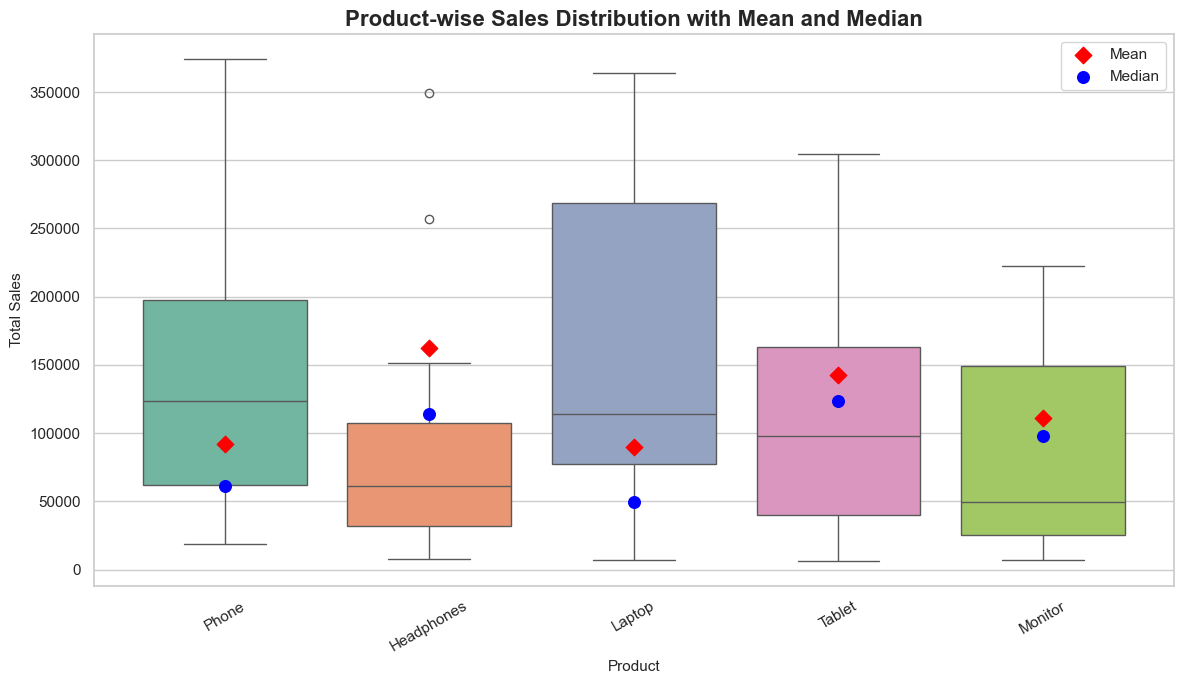

In [191]:
# ==========================================
# PRODUCT-WISE SALES WITH MEAN AND MEDIAN
# ==========================================

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x='Product',
    y='Total_Sales',
    hue='Product',
    palette='Set2',
    legend=False
)

# Calculate mean and median
product_stats = df.groupby('Product')['Total_Sales'].agg(
    ['mean', 'median']
)

for index, product in enumerate(product_stats.index):

    mean_value = product_stats.loc[product, 'mean']
    median_value = product_stats.loc[product, 'median']

    plt.scatter(
        index,
        mean_value,
        color='red',
        marker='D',
        s=70,
        zorder=5,
        label='Mean' if index == 0 else ''
    )

    plt.scatter(
        index,
        median_value,
        color='blue',
        marker='o',
        s=70,
        zorder=5,
        label='Median' if index == 0 else ''
    )

plt.title(
    'Product-wise Sales Distribution with Mean and Median',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Product')
plt.ylabel('Total Sales')

plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()

plt.savefig(
    'visualizations/sales_statistical_annotations.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [155]:
# Statistical summary by product
sales_summary = df.groupby('Product')['Total_Sales'].agg(
    Mean_Sales='mean',
    Median_Sales='median',
    Std_Deviation='std',
    Minimum_Sales='min',
    Maximum_Sales='max'
).round(2)

print("========== SALES SUMMARY BY PRODUCT ==========")
display(sales_summary)

========== SALES SUMMARY BY PRODUCT ==========


,Mean_Sales,Median_Sales,Std_Deviation,Minimum_Sales,Maximum_Sales
Product,,,,,
Headphones,92268.87,61624.0,96176.96,7647,349510
Laptop,162050.42,113720.0,116569.89,7148,363870
Monitor,89871.40,49280.0,77595.27,6720,222330
Phone,142969.70,123922.5,107191.55,18616,373932
Tablet,110936.15,97788.5,82366.53,6540,304465


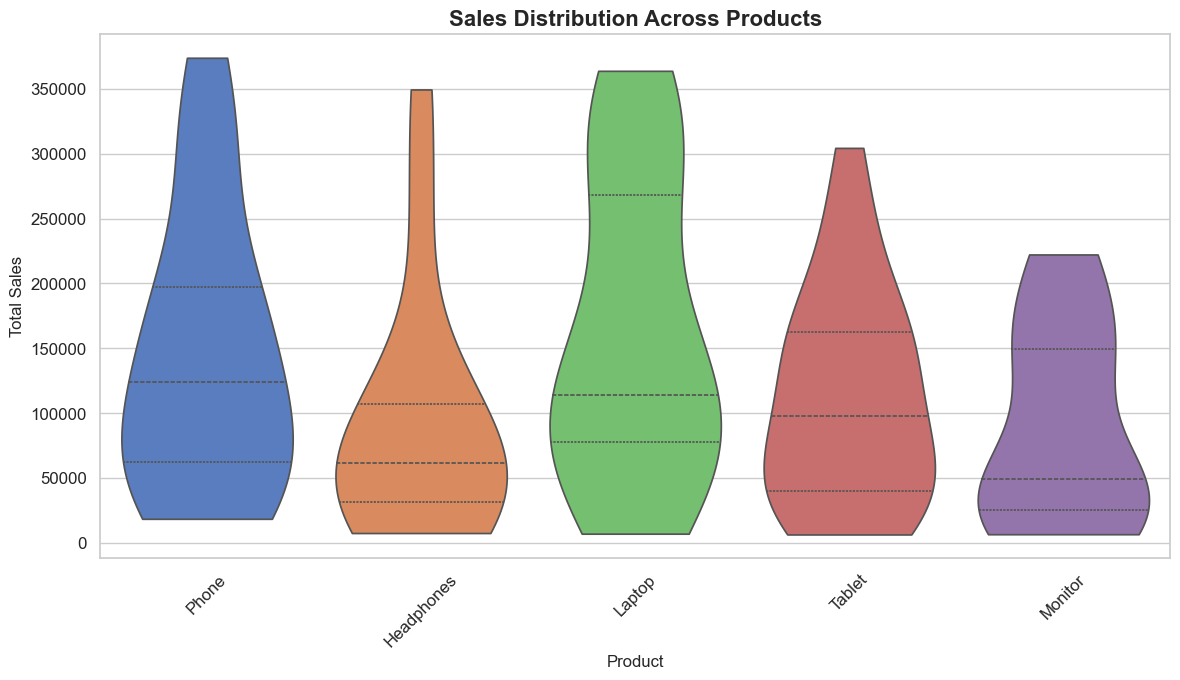

In [156]:
# Violin Plot - Sales Distribution

plt.figure(figsize=(12, 7))

sns.violinplot(
    data=df,
    x='Product',
    y='Total_Sales',
    hue='Product',
    palette='muted',
    inner='quart',
    cut=0,
    legend=False
)

plt.title(
    'Sales Distribution Across Products',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Product')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    'visualizations/violin_sales_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [157]:
# Outlier Detection using IQR

Q1 = df['Total_Sales'].quantile(0.25)
Q3 = df['Total_Sales'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("========== IQR OUTLIER ANALYSIS ==========")

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))

print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

print("==========================================")

========== IQR OUTLIER ANALYSIS ==========
Q1: 39517.5
Q3: 175792.5
IQR: 136275.0
Lower Bound: -164895.0
Upper Bound: 380205.0


In [158]:
# Identify potential outliers

outliers = df[
    (df['Total_Sales'] < lower_bound) |
    (df['Total_Sales'] > upper_bound)
]

print("========== OUTLIER RESULTS ==========")

print("Total Sales Records:", len(df))
print("Potential Outliers:", len(outliers))

print(
    "Outlier Percentage:",
    round((len(outliers) / len(df)) * 100, 2),
    "%"
)

print("\nOutlier Details:")
display(outliers)

print("=====================================")

========== OUTLIER RESULTS ==========
Total Sales Records: 100
Potential Outliers: 0
Outlier Percentage: 0.0 %

Outlier Details:


,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales


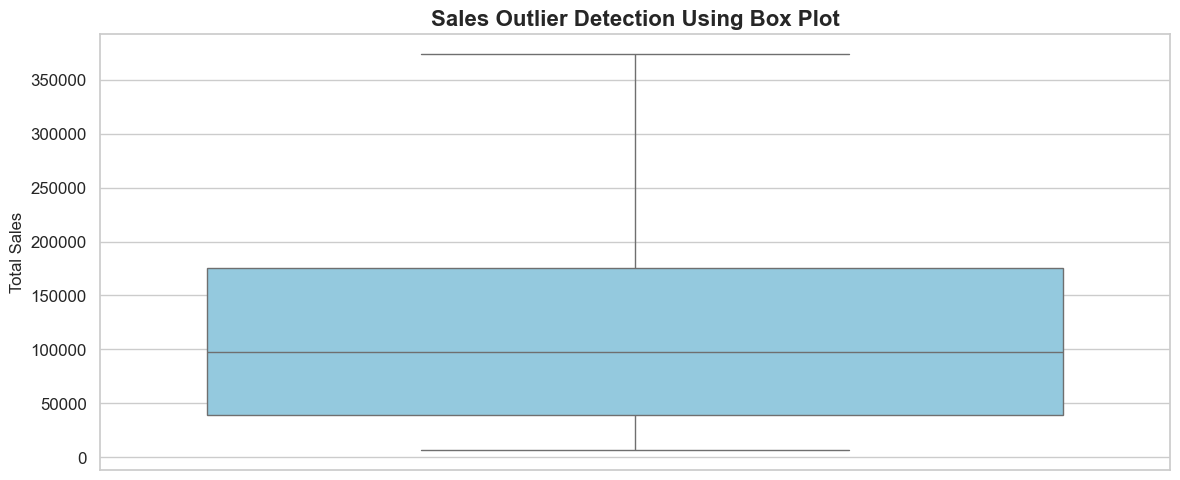

In [159]:
# Box Plot - Sales Outlier Detection

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df,
    y='Total_Sales',
    color='skyblue'
)

plt.title(
    'Sales Outlier Detection Using Box Plot',
    fontsize=16,
    fontweight='bold'
)

plt.ylabel('Total Sales')

plt.tight_layout()

plt.savefig(
    'visualizations/sales_outlier_boxplot.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [160]:
# Top 10 Sales Transactions

top_transactions = df.nlargest(
    10,
    'Total_Sales'
)[[
    'Date',
    'Product',
    'Quantity',
    'Price',
    'Customer_ID',
    'Region',
    'Total_Sales'
]]

print("========== TOP 10 SALES TRANSACTIONS ==========")

display(top_transactions)

print("================================================")

========== TOP 10 SALES TRANSACTIONS ==========


,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales
15,2024-01-16,Phone,9,41548,CUST016,South,373932
6,2024-01-07,Laptop,9,40430,CUST007,South,363870
82,2024-03-23,Laptop,8,43861,CUST083,North,350888
72,2024-03-13,Headphones,7,49930,CUST073,West,349510
19,2024-01-20,Laptop,8,41749,CUST020,North,333992
83,2024-03-24,Phone,8,40518,CUST084,South,324144
69,2024-03-10,Laptop,9,35418,CUST070,South,318762
4,2024-01-05,Laptop,8,39835,CUST005,North,318680
64,2024-03-05,Phone,7,44652,CUST065,South,312564
27,2024-01-28,Tablet,7,43495,CUST028,North,304465


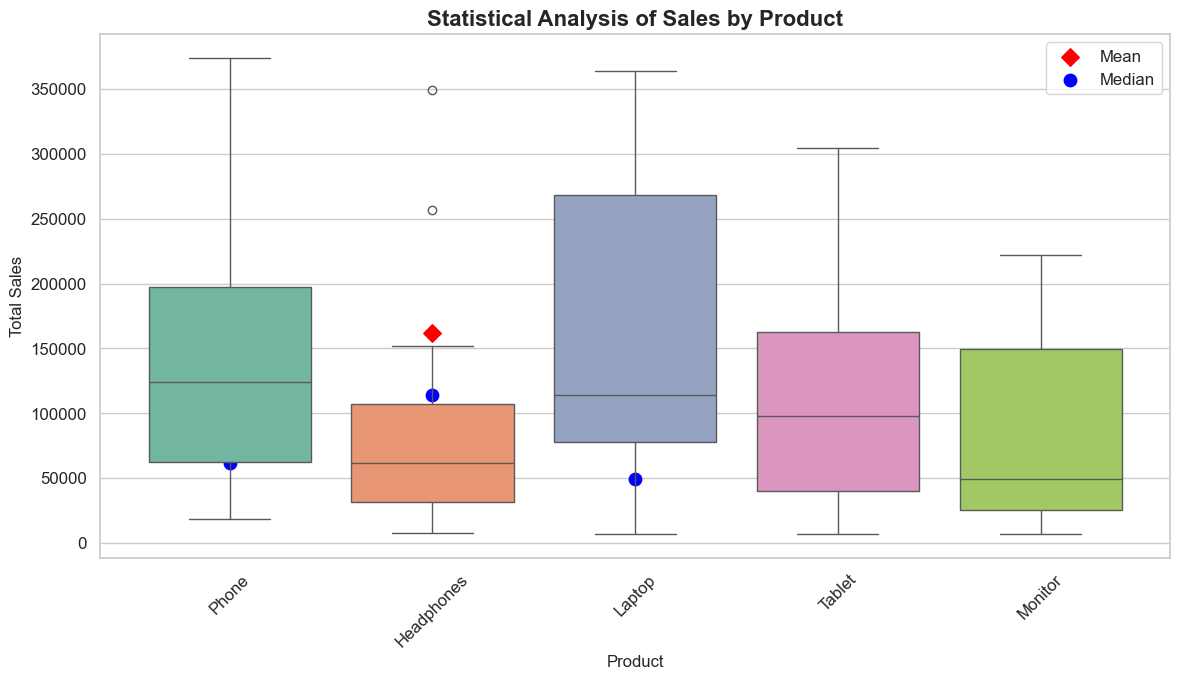

In [161]:
# Statistical Annotations - Mean and Median

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x='Product',
    y='Total_Sales',
    hue='Product',
    palette='Set2',
    legend=False
)

# Calculate mean and median by product
product_stats = df.groupby('Product')['Total_Sales'].agg(
    ['mean', 'median']
)

# Add mean and median markers
for index, product in enumerate(product_stats.index):

    mean_value = product_stats.loc[product, 'mean']
    median_value = product_stats.loc[product, 'median']

    # Mean marker
    plt.scatter(
        index,
        mean_value,
        color='red',
        marker='D',
        s=80,
        label='Mean' if index == 0 else ''
    )

    # Median marker
    plt.scatter(
        index,
        median_value,
        color='blue',
        marker='o',
        s=80,
        label='Median' if index == 0 else ''
    )

plt.title(
    'Statistical Analysis of Sales by Product',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Product')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig(
    'visualizations/statistical_annotations.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [162]:
# Statistical Summary by Product

sales_summary = df.groupby('Product')['Total_Sales'].agg(
    Mean='mean',
    Median='median',
    Standard_Deviation='std',
    Minimum='min',
    Maximum='max'
).round(2)

print("========== SALES SUMMARY ==========")

display(sales_summary)

print("===================================")

========== SALES SUMMARY ==========


,Mean,Median,Standard_Deviation,Minimum,Maximum
Product,,,,,
Headphones,92268.87,61624.0,96176.96,7647,349510
Laptop,162050.42,113720.0,116569.89,7148,363870
Monitor,89871.40,49280.0,77595.27,6720,222330
Phone,142969.70,123922.5,107191.55,18616,373932
Tablet,110936.15,97788.5,82366.53,6540,304465


In [163]:
# Select relevant numerical columns

numerical_df = df[
    ['Quantity', 'Price', 'Total_Sales']
]

print("Selected Numerical Features:")
print(numerical_df.columns.tolist())

print("\nNumerical Dataset Preview:")
display(numerical_df.head())

Selected Numerical Features:
['Quantity', 'Price', 'Total_Sales']

Numerical Dataset Preview:


,Quantity,Price,Total_Sales
0,7,37300,261100
1,4,15406,61624
2,2,21746,43492
3,1,30895,30895
4,8,39835,318680


In [164]:
# Select relevant numerical columns

numerical_df = df[
    ['Quantity', 'Price', 'Total_Sales']
]

print("Selected Numerical Features:")
display(numerical_df.head())
# Calculate correlation matrix

correlation_matrix = numerical_df.corr()

print("Correlation Matrix:")

display(correlation_matrix.round(3))

Selected Numerical Features:


,Quantity,Price,Total_Sales
0,7,37300,261100
1,4,15406,61624
2,2,21746,43492
3,1,30895,30895
4,8,39835,318680


Correlation Matrix:


,Quantity,Price,Total_Sales
Quantity,1.000,0.008,0.688
Price,0.008,1.000,0.646
Total_Sales,0.688,0.646,1.000


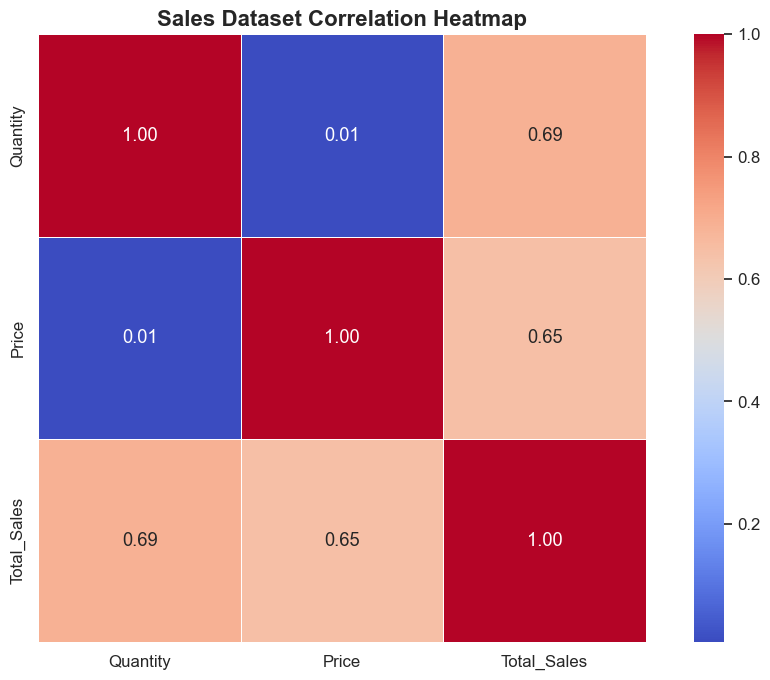

In [165]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title(
    'Sales Dataset Correlation Heatmap',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(
    'visualizations/correlation_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [166]:
# Import NumPy if not already imported
import numpy as np

# Create numerical dataset
numerical_df = df[['Quantity', 'Price', 'Total_Sales']]

# Calculate correlation matrix
correlation_matrix = numerical_df.corr()

display(correlation_matrix.round(3))

,Quantity,Price,Total_Sales
Quantity,1.000,0.008,0.688
Price,0.008,1.000,0.646
Total_Sales,0.688,0.646,1.000


In [167]:
import numpy as np

numerical_df = df[['Quantity', 'Price', 'Total_Sales']]

correlation_matrix = numerical_df.corr()

print("Correlation matrix created successfully!")
display(correlation_matrix)
# Extract correlation pairs
correlation_pairs = correlation_matrix.unstack()

# Remove self-correlations
correlation_pairs = correlation_pairs[
    correlation_pairs.index.get_level_values(0) !=
    correlation_pairs.index.get_level_values(1)
]

# Remove duplicate pairs
correlation_pairs = correlation_pairs.drop_duplicates()

# Sort by correlation strength
correlation_pairs = correlation_pairs.sort_values(
    key=abs,
    ascending=False
)

print("Strongest Correlation Relationships:")
display(correlation_pairs)

Correlation matrix created successfully!


,Quantity,Price,Total_Sales
Quantity,1.000000,0.008014,0.688107
Price,0.008014,1.000000,0.646131
Total_Sales,0.688107,0.646131,1.000000


Strongest Correlation Relationships:


Quantity  Total_Sales    0.688107
Price     Total_Sales    0.646131
Quantity  Price          0.008014
dtype: float64

In [168]:
# Quantity and Total Sales Correlation

quantity_sales_corr = df['Quantity'].corr(df['Total_Sales'])

print(
    f"Quantity-Total Sales Correlation: {quantity_sales_corr:.3f}"
)

if quantity_sales_corr > 0.7:
    print("Strong positive relationship")

elif quantity_sales_corr > 0.3:
    print("Moderate positive relationship")

elif quantity_sales_corr > 0:
    print("Weak positive relationship")

elif quantity_sales_corr < -0.3:
    print("Negative relationship")

else:
    print("Very weak or negligible relationship")

Quantity-Total Sales Correlation: 0.688
Moderate positive relationship


In [169]:
import os

print("Day 3 Visualizations:")

for file in os.listdir("visualizations"):
    if "correlation" in file:
        print("✔", file)

Day 3 Visualizations:
✔ advanced_correlation_heatmap.png
✔ correlation_heatmap.png


Date column converted successfully!
Monthly sales data prepared!


,Month,Total_Sales
0,2024-01,4120524
1,2024-02,2656050
2,2024-03,4485006
3,2024-04,1103468


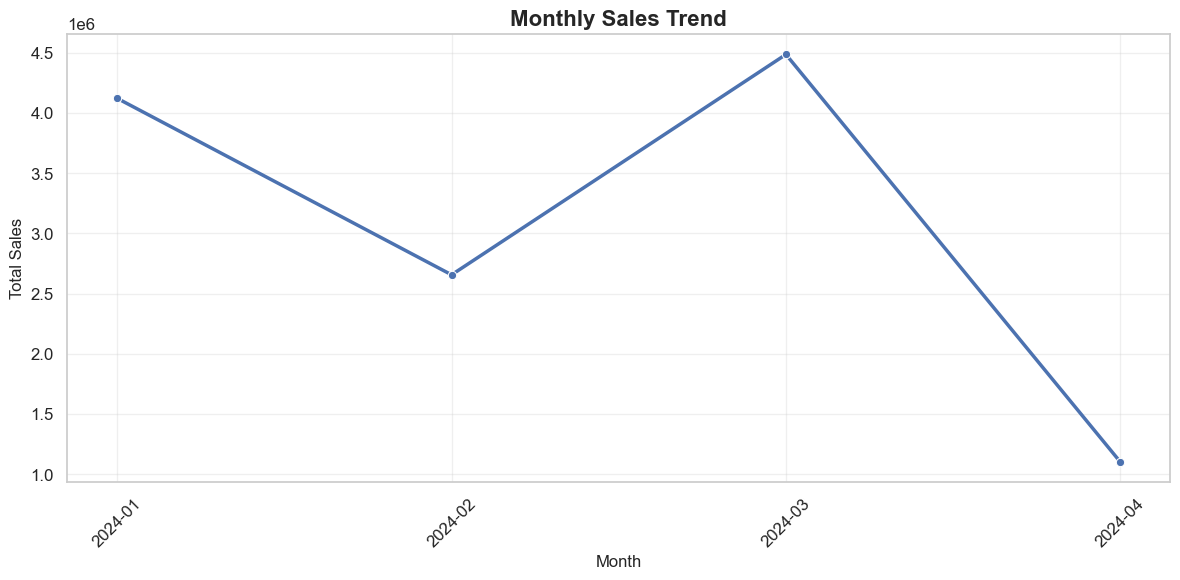

In [170]:
# Convert Date into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Extract month and year
df['Month'] = df['Date'].dt.to_period('M')

print("Date column converted successfully!")
# Monthly sales aggregation
monthly_sales = (
    df.groupby('Month')['Total_Sales']
    .sum()
    .reset_index()
)

monthly_sales['Month'] = monthly_sales['Month'].astype(str)

print("Monthly sales data prepared!")

display(monthly_sales.head())
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales,
    x='Month',
    y='Total_Sales',
    marker='o',
    linewidth=2.5
)

plt.title('Monthly Sales Trend', fontsize=16, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    'visualizations/monthly_sales_trend.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Data preparation completed successfully!


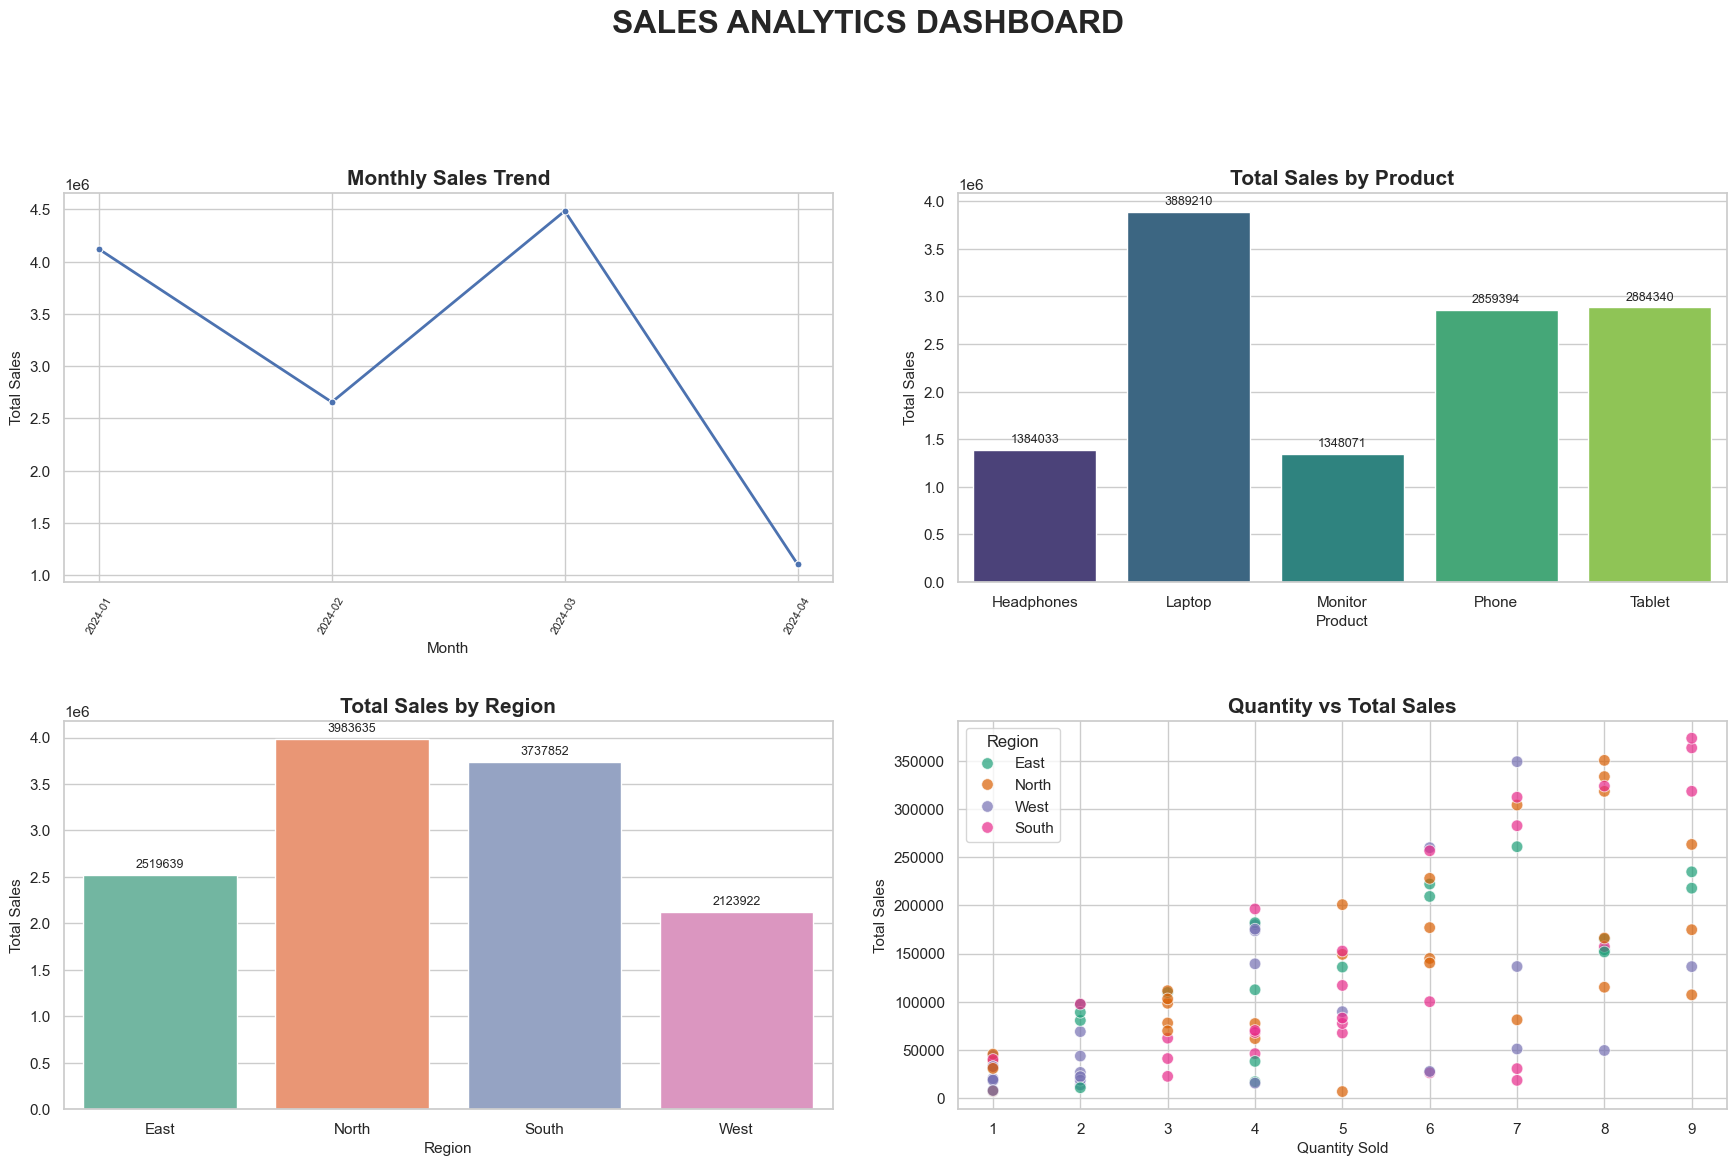


SALES DASHBOARD CREATED SUCCESSFULLY
Dashboard saved at:
visualizations/sales_subplot_dashboard.png


In [171]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ------------------------------------------------------------
# 1. VISUALIZATION SETTINGS
# ------------------------------------------------------------

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep"
)

plt.rcParams['figure.figsize'] = (18, 12)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11

# Create visualization folder
os.makedirs("visualizations", exist_ok=True)

# ------------------------------------------------------------
# 2. DATA PREPARATION
# ------------------------------------------------------------

df['Date'] = pd.to_datetime(df['Date'])

# Extract month and year
df['Month'] = df['Date'].dt.to_period('M').astype(str)

# Monthly sales aggregation
monthly_sales = (
    df.groupby('Month')['Total_Sales']
    .sum()
    .reset_index()
)

# Product-wise sales
product_sales = (
    df.groupby('Product')['Total_Sales']
    .sum()
    .reset_index()
)

# Region-wise sales
region_sales = (
    df.groupby('Region')['Total_Sales']
    .sum()
    .reset_index()
)

print("Data preparation completed successfully!")

# ------------------------------------------------------------
# 3. CREATE 2x2 DASHBOARD
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(18, 12)
)

fig.patch.set_facecolor('white')

# ------------------------------------------------------------
# CHART 1: MONTHLY SALES TREND
# ------------------------------------------------------------

sns.lineplot(
    data=monthly_sales,
    x='Month',
    y='Total_Sales',
    marker='o',
    linewidth=2,
    markersize=5,
    ax=axes[0, 0]
)

axes[0, 0].set_title(
    'Monthly Sales Trend',
    fontsize=15,
    fontweight='bold'
)

axes[0, 0].set_xlabel('Month')
axes[0, 0].set_ylabel('Total Sales')

axes[0, 0].tick_params(
    axis='x',
    rotation=60,
    labelsize=8
)

# ------------------------------------------------------------
# CHART 2: SALES BY PRODUCT
# ------------------------------------------------------------

sns.barplot(
    data=product_sales,
    x='Product',
    y='Total_Sales',
    hue='Product',
    palette='viridis',
    legend=False,
    ax=axes[0, 1]
)

axes[0, 1].set_title(
    'Total Sales by Product',
    fontsize=15,
    fontweight='bold'
)

axes[0, 1].set_xlabel('Product')
axes[0, 1].set_ylabel('Total Sales')

for container in axes[0, 1].containers:
    axes[0, 1].bar_label(
        container,
        fmt='%.0f',
        padding=3,
        fontsize=9
    )

# ------------------------------------------------------------
# CHART 3: SALES BY REGION
# ------------------------------------------------------------

sns.barplot(
    data=region_sales,
    x='Region',
    y='Total_Sales',
    hue='Region',
    palette='Set2',
    legend=False,
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    'Total Sales by Region',
    fontsize=15,
    fontweight='bold'
)

axes[1, 0].set_xlabel('Region')
axes[1, 0].set_ylabel('Total Sales')

for container in axes[1, 0].containers:
    axes[1, 0].bar_label(
        container,
        fmt='%.0f',
        padding=3,
        fontsize=9
    )

# ------------------------------------------------------------
# CHART 4: QUANTITY VS TOTAL SALES
# ------------------------------------------------------------

sns.scatterplot(
    data=df,
    x='Quantity',
    y='Total_Sales',
    hue='Region',
    alpha=0.7,
    palette='Dark2',
    s=70,
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    'Quantity vs Total Sales',
    fontsize=15,
    fontweight='bold'
)

axes[1, 1].set_xlabel('Quantity Sold')
axes[1, 1].set_ylabel('Total Sales')

axes[1, 1].legend(title='Region')

# ------------------------------------------------------------
# 4. DASHBOARD TITLE
# ------------------------------------------------------------

fig.suptitle(
    'SALES ANALYTICS DASHBOARD',
    fontsize=23,
    fontweight='bold',
    y=0.99
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95],
    pad=2.5
)

# ------------------------------------------------------------
# 5. SAVE DASHBOARD
# ------------------------------------------------------------

plt.savefig(
    'visualizations/sales_subplot_dashboard.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print("\n===================================")
print("SALES DASHBOARD CREATED SUCCESSFULLY")
print("===================================")

print("Dashboard saved at:")
print("visualizations/sales_subplot_dashboard.png")

In [100]:
import os

file_path = "visualizations/sales_subplot_dashboard.png"

if os.path.exists(file_path):
    print("Dashboard successfully saved!")
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")
else:
    print("Dashboard file not found!")

Dashboard successfully saved!
File size: 573.86 KB


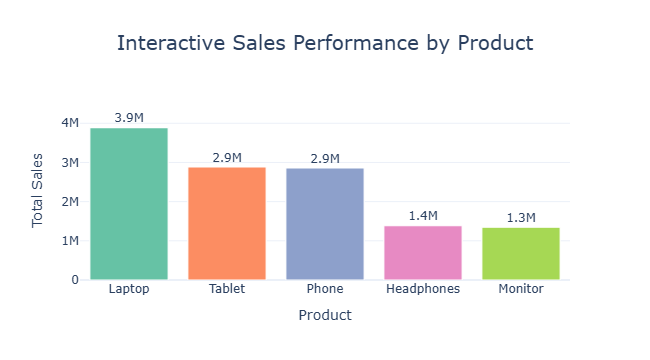

Interactive product chart saved successfully!


In [172]:
# ==========================================
# DAY 5 - INTERACTIVE PRODUCT PERFORMANCE
# ==========================================

import plotly.express as px

# Aggregate sales by product
product_sales = (
    df.groupby('Product')['Total_Sales']
    .sum()
    .reset_index()
    .sort_values('Total_Sales', ascending=False)
)

# Create interactive bar chart
fig = px.bar(
    product_sales,
    x='Product',
    y='Total_Sales',
    color='Product',
    text_auto='.2s',
    hover_data={
        'Total_Sales': ':,.2f'
    },
    title='Interactive Sales Performance by Product',
    template='plotly_white',
    color_discrete_sequence=px.colors.qualitative.Set2
)

fig.update_layout(
    title_x=0.5,
    title_font_size=20,
    xaxis_title='Product',
    yaxis_title='Total Sales',
    showlegend=False,
    hovermode='x unified'
)

fig.update_traces(
    marker_line_width=1.2,
    textposition='outside'
)

fig.show()

# Save interactive visualization
fig.write_html(
    'visualizations/interactive_product_sales.html'
)

print("Interactive product chart saved successfully!")

In [173]:
import os

file_path = 'visualizations/interactive_category_sales.html'

print("File exists:", os.path.exists(file_path))

File exists: True


In [174]:
# ==========================================
# CUSTOMER SEGMENTATION ANALYSIS
# ==========================================

# Group sales data by customer
customer_data = df.groupby('Customer_ID').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Transactions=('Customer_ID', 'count'),
    Average_Sales=('Total_Sales', 'mean'),
    Region=('Region', 'first')
).reset_index()

# Rank customers by total sales
customer_data = customer_data.sort_values(
    'Total_Sales',
    ascending=False
)

print("Customer data prepared successfully!")

print("Total Unique Customers:", customer_data['Customer_ID'].nunique())

print("\nTop 10 Customers by Sales:")

display(customer_data.head(10))


Customer data prepared successfully!
Total Unique Customers: 100

Top 10 Customers by Sales:


,Customer_ID,Total_Sales,Total_Quantity,Total_Transactions,Average_Sales,Region
15,CUST016,373932,9,1,373932.0,South
6,CUST007,363870,9,1,363870.0,South
82,CUST083,350888,8,1,350888.0,North
72,CUST073,349510,7,1,349510.0,West
19,CUST020,333992,8,1,333992.0,North
83,CUST084,324144,8,1,324144.0,South
69,CUST070,318762,9,1,318762.0,South
4,CUST005,318680,8,1,318680.0,North
64,CUST065,312564,7,1,312564.0,South
27,CUST028,304465,7,1,304465.0,North


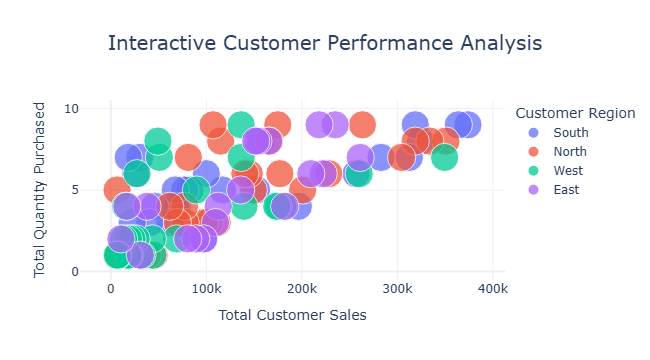

Interactive customer performance chart saved successfully!


In [175]:
# ==========================================
# INTERACTIVE CUSTOMER PERFORMANCE ANALYSIS
# ==========================================

fig = px.scatter(
    customer_data,
    x='Total_Sales',
    y='Total_Quantity',
    size='Total_Transactions',
    color='Region',
    hover_name='Customer_ID',
    hover_data={
        'Total_Sales': ':.2f',
        'Total_Quantity': True,
        'Total_Transactions': True
    },
    title='Interactive Customer Performance Analysis',
    labels={
        'Total_Sales': 'Total Customer Sales',
        'Total_Quantity': 'Total Quantity Purchased',
        'Total_Transactions': 'Number of Transactions',
        'Region': 'Customer Region'
    },
    template='plotly_white',
    opacity=0.75
)

fig.update_layout(
    title_x=0.5,
    title_font_size=20,
    hovermode='closest'
)

fig.show()

# Save interactive chart
fig.write_html(
    'visualizations/customer_performance.html'
)

print("Interactive customer performance chart saved successfully!")

In [176]:
# ==========================================
# CUSTOMER PERFORMANCE BY REGION
# ==========================================

segment_analysis = customer_data.groupby('Region').agg(
    Total_Customers=('Customer_ID', 'nunique'),
    Total_Sales=('Total_Sales', 'sum'),
    Total_Quantity=('Total_Quantity', 'sum'),
    Average_Sales=('Total_Sales', 'mean')
).round(2)

segment_analysis = segment_analysis.sort_values(
    'Total_Sales',
    ascending=False
)

print("CUSTOMER PERFORMANCE BY REGION")

display(segment_analysis)

CUSTOMER PERFORMANCE BY REGION


,Total_Customers,Total_Sales,Total_Quantity,Average_Sales
Region,,,,
North,28,3983635,147,142272.68
South,27,3737852,143,138438.96
East,19,2519639,94,132612.58
West,26,2123922,94,81689.31


In [177]:
import os

file_path = 'visualizations/customer_segmentation.html'

print("File exists:", os.path.exists(file_path))

File exists: True


In [178]:
# ==========================================
# INTERACTIVE REGIONAL SALES ANALYSIS
# ==========================================

region_data = df.groupby('Region').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Customers=('Customer_ID', 'nunique'),
    Total_Quantity=('Quantity', 'sum'),
    Average_Sales=('Total_Sales', 'mean'),
    Total_Transactions=('Customer_ID', 'count')
).reset_index()

# Sort regions by total sales
region_data = region_data.sort_values(
    'Total_Sales',
    ascending=False
)

print("Regional data prepared successfully!")

display(region_data)

Regional data prepared successfully!


,Region,Total_Sales,Total_Customers,Total_Quantity,Average_Sales,Total_Transactions
1,North,3983635,28,147,142272.678571,28
2,South,3737852,27,143,138438.962963,27
0,East,2519639,19,94,132612.578947,19
3,West,2123922,26,94,81689.307692,26


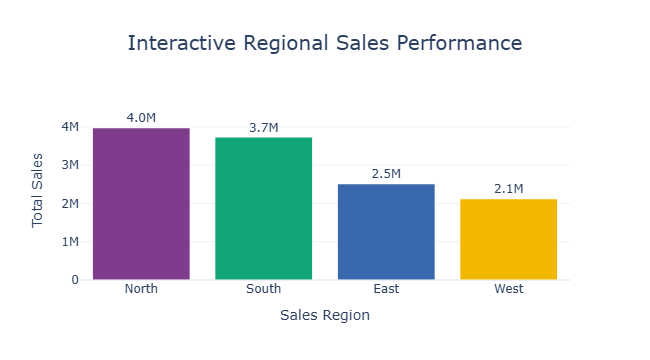

Regional sales chart saved successfully!


In [179]:
# ==========================================
# PLOTLY - REGIONAL SALES PERFORMANCE
# ==========================================

fig = px.bar(
    region_data,
    x='Region',
    y='Total_Sales',
    color='Region',
    text_auto='.2s',
    hover_data={
        'Total_Sales': ':,.2f',
        'Total_Customers': True,
        'Total_Quantity': True,
        'Average_Sales': ':,.2f',
        'Total_Transactions': True
    },
    title='Interactive Regional Sales Performance',
    template='plotly_white',
    color_discrete_sequence=px.colors.qualitative.Bold
)

fig.update_layout(
    title_x=0.5,
    title_font_size=20,
    xaxis_title='Sales Region',
    yaxis_title='Total Sales',
    showlegend=False,
    hovermode='x unified'
)

fig.update_traces(
    textposition='outside',
    marker_line_width=1.2
)

fig.show()

# Save interactive chart
fig.write_html(
    'visualizations/interactive_regional_sales.html'
)

print("Regional sales chart saved successfully!")

In [180]:
region_data = df.groupby('Region').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Customers=('Customer_ID', 'nunique'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Transactions=('Customer_ID', 'count')
).reset_index()

print("Regional data prepared successfully!")
display(region_data)

Regional data prepared successfully!


,Region,Total_Sales,Total_Customers,Total_Quantity,Total_Transactions
0,East,2519639,19,94,19
1,North,3983635,28,147,28
2,South,3737852,27,143,27
3,West,2123922,26,94,26


In [181]:
region_data = df.groupby('Region').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Customers=('Customer_ID', 'nunique'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Transactions=('Customer_ID', 'count')
).reset_index()

print("Regional data prepared successfully!")
display(region_data)
print("========== REGIONAL PERFORMANCE ==========")

best_sales_region = region_data.loc[
    region_data['Total_Sales'].idxmax()
]

best_quantity_region = region_data.loc[
    region_data['Total_Quantity'].idxmax()
]

print(
    "Highest Revenue Region:",
    best_sales_region['Region']
)

print(
    "Highest Quantity Region:",
    best_quantity_region['Region']
)

print(
    "Highest Regional Sales:",
    round(best_sales_region['Total_Sales'], 2)
)

print(
    "Highest Regional Quantity:",
    best_quantity_region['Total_Quantity']
)

print("\nRegional Performance Ranking:")

display(
    region_data.sort_values(
        'Total_Sales',
        ascending=False
    )
)

print("===========================================")

Regional data prepared successfully!


,Region,Total_Sales,Total_Customers,Total_Quantity,Total_Transactions
0,East,2519639,19,94,19
1,North,3983635,28,147,28
2,South,3737852,27,143,27
3,West,2123922,26,94,26


========== REGIONAL PERFORMANCE ==========
Highest Revenue Region: North
Highest Quantity Region: North
Highest Regional Sales: 3983635
Highest Regional Quantity: 147

Regional Performance Ranking:


,Region,Total_Sales,Total_Customers,Total_Quantity,Total_Transactions
1,North,3983635,28,147,28
2,South,3737852,27,143,27
0,East,2519639,19,94,19
3,West,2123922,26,94,26


In [182]:
import os

files = [
    'interactive_regional_sales.html',
    'interactive_regional_profit.html'
]

for file in files:
    path = os.path.join('visualizations', file)
    print(file, ":", os.path.exists(path))

interactive_regional_sales.html : True
interactive_regional_profit.html : True


In [183]:
# ==========================================
# PRODUCT PERFORMANCE ANALYSIS
# ==========================================

product_data = df.groupby('Product').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Average_Sales=('Total_Sales', 'mean'),
    Total_Transactions=('Product', 'count')
).reset_index()

product_data = product_data.sort_values(
    'Total_Sales',
    ascending=False
)

print("Product data prepared successfully!")

display(product_data)

Product data prepared successfully!


,Product,Total_Sales,Total_Quantity,Average_Sales,Total_Transactions
1,Laptop,3889210,136,162050.416667,24
4,Tablet,2884340,127,110936.153846,26
3,Phone,2859394,101,142969.700000,20
0,Headphones,1384033,48,92268.866667,15
2,Monitor,1348071,66,89871.400000,15


Product data prepared successfully!


,Product,Total_Sales,Total_Quantity,Average_Sales,Total_Transactions
0,Headphones,1384033,48,92268.866667,15
1,Laptop,3889210,136,162050.416667,24
2,Monitor,1348071,66,89871.400000,15
3,Phone,2859394,101,142969.700000,20
4,Tablet,2884340,127,110936.153846,26


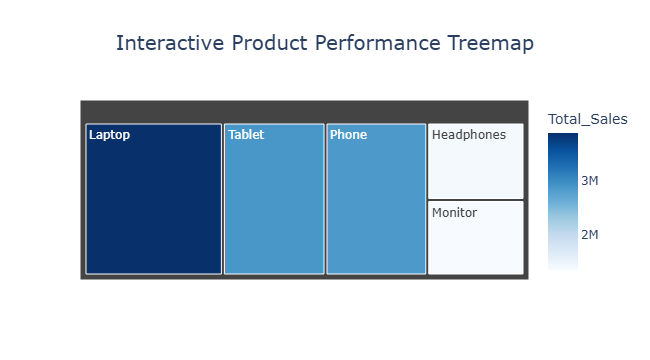

Product treemap saved successfully!


In [184]:
product_data = df.groupby('Product').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Average_Sales=('Total_Sales', 'mean'),
    Total_Transactions=('Product', 'count')
).reset_index()

print("Product data prepared successfully!")
display(product_data)
# ==========================================
# INTERACTIVE PRODUCT PERFORMANCE TREEMAP
# ==========================================

fig = px.treemap(
    product_data,
    path=['Product'],
    values='Total_Sales',
    color='Total_Sales',
    color_continuous_scale='Blues',
    hover_data={
        'Total_Sales': ':,.2f',
        'Total_Quantity': True,
        'Average_Sales': ':,.2f',
        'Total_Transactions': True
    },
    title='Interactive Product Performance Treemap',
    template='plotly_white'
)

fig.update_layout(
    title_x=0.5,
    title_font_size=20
)

fig.show()

fig.write_html(
    'visualizations/product_performance_treemap.html'
)

print("Product treemap saved successfully!")

In [185]:
# ==========================================
# TOP 5 PRODUCTS BY SALES
# ==========================================

product_data = df.groupby('Product').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Average_Sales=('Total_Sales', 'mean'),
    Total_Transactions=('Product', 'count')
).reset_index()

top_products = product_data.sort_values(
    'Total_Sales',
    ascending=False
).head(5)

print("========== TOP 5 PRODUCTS BY SALES ==========")
display(top_products)

========== TOP 5 PRODUCTS BY SALES ==========


,Product,Total_Sales,Total_Quantity,Average_Sales,Total_Transactions
1,Laptop,3889210,136,162050.416667,24
4,Tablet,2884340,127,110936.153846,26
3,Phone,2859394,101,142969.700000,20
0,Headphones,1384033,48,92268.866667,15
2,Monitor,1348071,66,89871.400000,15


In [186]:
import os

file_path = 'visualizations/product_performance_treemap.html'

print("Treemap saved:", os.path.exists(file_path))

Treemap saved: True


In [187]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Product dropdown
product_dropdown = widgets.Dropdown(
    options=['All'] + sorted(df['Product'].unique().tolist()),
    value='All',
    description='Product:'
)

output = widgets.Output()

def update_product_chart(change=None):

    with output:
        clear_output(wait=True)

        if product_dropdown.value == 'All':
            filtered_df = df.copy()
        else:
            filtered_df = df[
                df['Product'] == product_dropdown.value
            ]

        product_summary = filtered_df.groupby(
            'Product'
        )['Total_Sales'].sum().reset_index()

        fig = px.bar(
            product_summary,
            x='Product',
            y='Total_Sales',
            color='Product',
            text_auto='.2s',
            title=f"Sales Analysis - {product_dropdown.value}",
            template='plotly_white'
        )

        fig.show()

product_dropdown.observe(
    update_product_chart,
    names='value'
)

display(product_dropdown, output)

update_product_chart()

Dropdown(description='Product:', options=('All', 'Headphones', 'Laptop', 'Monitor', 'Phone', 'Tablet'), value=…

Output()

In [188]:
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [189]:
import os

print("HTML Visualizations:")
for file in sorted(os.listdir("visualizations")):
    if file.endswith(".html"):
        print("✔", file)

print("\nTotal HTML charts:",
      len([f for f in os.listdir("visualizations") if f.endswith(".html")]))

HTML Visualizations:
✔ customer_performance.html
✔ customer_segmentation.html
✔ interactive_category_sales.html
✔ interactive_product_sales.html
✔ interactive_regional_profit.html
✔ interactive_regional_sales.html
✔ product_performance_treemap.html

Total HTML charts: 7


In [190]:
# Dashboard title
st.title("📊 Interactive Sales Analytics Dashboard")
st.markdown("### Product Sales Performance Analysis")

# Load dataset
@st.cache_data
def load_data():
    df = pd.read_csv("data/sales_data.csv")
    df["Date"] = pd.to_datetime(df["Date"])
    return df

df = load_data()

st.success("Dataset loaded successfully!")
st.write("Dataset shape:", df.shape)
st.write("Available columns:", df.columns.tolist())

2026-11-19 04:38:13.746 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-19 04:38:13.747 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-19 04:38:13.748 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-19 04:38:13.749 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-19 04:38:13.750 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-19 04:38:13.751 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-19 04:38:13.752 No runtime found, using MemoryCacheStorageManager
2026-11-19 04:38:13.755 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-19 04:38:13.756 Thread 'MainThread':